# Performance evaluation for **In Silico Combined Reference Genome**

## 0. Imports and path assignments

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay
import sys
import os
sys.path.append(os.path.abspath(os.path.join("..")))
from helper.visualization import *
from helper.metrics import * 

from warnings import simplefilter
simplefilter("ignore")

In [2]:
data_dir = Path("/omics/groups/OE0219/internal/altendorfer/epiproper/read_sorting_benchmark/data")
method = "icrg" # Add more methods here
fig_dir = Path.cwd() / "figures"
fig_dir.mkdir(exist_ok=True, parents=True)

## 1. Load data

In [3]:
df = read_evaluations(data_dir, method)

In [4]:
df["Human_Ratio"] = [float(s.rstrip('p')) for s in df["Mixture"]]

## 2. Confusion Matrix

In [5]:
df = assign_confusion_matrix(df, method="icrg")

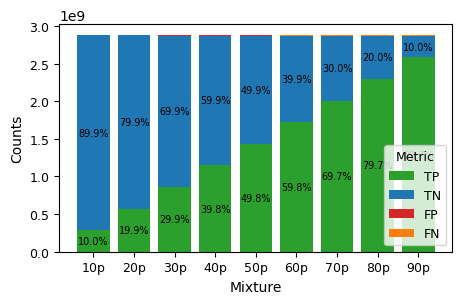

In [6]:
figsize = mm_to_inches((120, 80))
plot_stacked_confusion_bar(
    df,
    save=True,
    fig_dir=fig_dir,
    figsize=figsize
)

## 3. Calculate performance metrics

In [10]:
df_metrics = calculate_metrics(df)

## 4. Save dataframe

In [11]:
df_metrics["Method"] = "ICRG"

In [13]:
out_dir = Path.cwd() / "results"
out_dir.mkdir(exist_ok=True)

df_metrics.to_csv(out_dir / "icrg.csv", index=False)